In [1]:
# --- bootstrap: dodaj katalog projektu do sys.path (dziala z notebooks/ i z root) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while not (_p / 'config.py').exists() and _p != _p.parent:
    _p = _p.parent
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))
from IPython.display import display

import config


# Notebook 00: eksploracyjna analiza danych

Etap przygotowuje korpus do dalszej pracy: czyści nagłówki, dzieli je chronologicznie i opisuje rozkłady, na których opierają się decyzje w notebookach `01a` i `01b`.

Wydawcy: **0** Niezależna, **1** OKO.press, **2** RP (Rzeczpospolita).

Wejście: `data/korpus_surowy.csv`. Wyjście: `data/train_data.csv`, `data/valid_data.csv`, `data/test_data.csv` oraz `data/split_info.json`.

Logika siedzi w `src/data.py` i `src/visualization.py`, notebook ją wywołuje i pokazuje wyniki.

## 1. Wczytanie, lematyzacja i podział

Jedno wywołanie wczytuje surowy korpus, usuwa redakcyjne dopiski w nawiasach kwadratowych, ogranicza zakres do obserwacji od 2022 roku, dopisuje lematy i zapisuje podzbiory.

Granice podziału wyznacza data, nie udział obserwacji: test to ostatni rok korpusu, walidacja rok go poprzedzający, a trening cała wcześniejsza część. Długość obu okien ustalają `config.VALID_YEARS` i `config.TEST_YEARS`. Podział po dacie zamiast losowego zapobiega wyciekowi informacji z przyszłości - model nie widzi w trakcie uczenia nagłówków późniejszych niż te, na których jest oceniany. Gwarancji pilnują testy w `tests/`.

Lematyzacja morfeuszem trwa kilka minut; `lemmatize=False` ją pomija, ale notebook `01b` oczekuje kolumny `lemmatized_text`.

In [2]:
from src import data as ds

wyniki = ds.prepare_splits(lemmatize=True)

korpus = wyniki["corpus"]
print(f"Korpus roboczy: {len(korpus)} nagłówków "
      f"({korpus['date_parsed'].min().date()} - {korpus['date_parsed'].max().date()})")
for nazwa in ("train", "valid", "test"):
    zbior = wyniki[nazwa]
    print(f"  {nazwa:<6} {len(zbior):>6}  "
          f"{zbior['date_parsed'].min().date()} - {zbior['date_parsed'].max().date()}")
korpus.head()

Korpus roboczy: 55914 nagłówków (2022-01-01 - 2026-02-04)
  train   27264  2022-01-01 - 2024-02-03
  valid   15843  2024-02-04 - 2025-02-03
  test    12807  2025-02-04 - 2026-02-04


,text,label,date,date_parsed,lemmatized_text
0,"Epidemia: pędzimy na zderzenie ze ścianą, tym ...",1,"01.01.2022, 07:34",2022-01-01,epidemia pędzić zderzenie ściana świadomie
1,Rodzinny Kapitał Opiekuńczy cieszy się ogromny...,0,"01.01.2022, 12:48",2022-01-01,rodzinny kapitał opiekuńczy cieszyć ogromny za...
2,Trzaskowski bagatelizował Nord Stream 2. Jak t...,0,"01.01.2022, 22:52",2022-01-01,trzaskowski bagatelizować nord stream słowo re...
3,Zamknięcie rosyjskiego Memoriału to część przy...,1,"01.01.2022, 09:40",2022-01-01,zamknąć rosyjski memoriał część przygotowanie ...
4,"Nowy rok, ale u Tomasza Lisa bez zmian. Zapowi...",0,"01.01.2022, 21:40",2022-01-01,nowy rok tomasz lis zmiana zapowiadać proces p...


## 2. Rozkład obserwacji między wydawców

Klasy są nierówne, dlatego notebook `01a` uczy klasyfikator ze stratą ważoną, a wyniki raportuje w F1-macro, nie w trafności.

In [3]:
for nazwa, (liczba, udzial) in wyniki["class_distribution"].items():
    print(f"  {nazwa:<12} {liczba:>6}  ({udzial}%)")

print()
print("Rozkład w podzbiorach:")
for nazwa in ("train", "valid", "test"):
    rozklad = ds.class_distribution(wyniki[nazwa])
    opis = "  ".join(f"{k}: {v[1]}%" for k, v in rozklad.items())
    print(f"  {nazwa:<6} {opis}")

  Niezależna    20892  (37.4%)
  OKO.press     19781  (35.4%)
  RP            15241  (27.3%)

Rozkład w podzbiorach:
  train  Niezależna: 36.3%  OKO.press: 33.2%  RP: 30.5%
  valid  Niezależna: 35.6%  OKO.press: 39.2%  RP: 25.2%
  test   Niezależna: 41.9%  OKO.press: 35.3%  RP: 22.8%


## 3. Statystyki opisowe i ubytek rekordów

Jedno wywołanie liczy dwie tabele. Pierwsza podaje liczebności w podzbiorach, średnią liczbę słów i średnią liczbę tokenów BPE na nagłówek, osobno dla każdego wydawcy. Druga rozbija ubytek rekordów na kroki czyszczenia i podaje odsetek nagłówków z dopiskami w nawiasach, również per wydawca - to ta asymetria uzasadnia usuwanie dopisków.

Tokeny BPE liczone są bez znaczników specjalnych, więc opisują sam nagłówek; wejście modelu jest o dwa tokeny dłuższe. Krok wymaga tokenizatora HerBERTa i trwa kilkanaście sekund.


In [ ]:
opis = ds.descriptive_stats()

display(opis["per_publisher"])
display(opis["cleaning"])


## 4. Liczebności w czasie

Rysunek pokazuje, czy udział wydawców jest stabilny w całym okresie. Zmiana proporcji między zbiorem uczącym a testowym oznaczałaby, że spadek trafności na teście może pochodzić ze zmiany składu korpusu, a nie ze zmiany języka nagłówków.

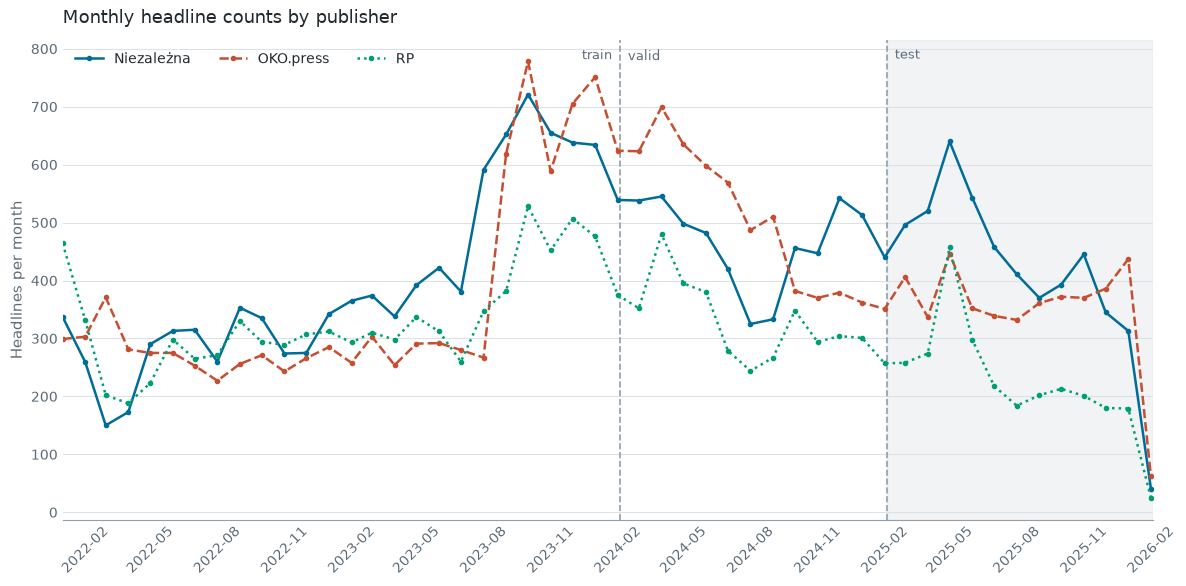

In [4]:
from src.visualization import plot_monthly_counts

fig = plot_monthly_counts(
    korpus,
    save_path=config.FIGURES / "05_liczebnosci_miesieczne.png",
)

## 5. N-gramy

Zestawienia liczone na tekstach po lematyzacji, bez stop słów. Służą do oceny, czy w korpusie nie dominują formy czysto redakcyjne, które niosłyby tożsamość wydawcy zamiast treści nagłówka.

In [5]:
teksty = korpus["lemmatized_text"].tolist()

for n in (1, 2, 3):
    print()
    print(f"Najczęstsze {n}-gramy:")
    display(ds.top_ngrams(teksty, n=n, top=30).head(15))


Najczęstsze 1-gramy:


,ngram,liczba
0,tusk,7013
1,pis,6024
2,polski,4407
3,rząd,3359
4,prezydent,3176
5,chcieć,3032
6,mieć,3019
7,wybory,2636
8,polska,2469
9,kaczyński,2170



Najczęstsze 2-gramy:


,ngram,liczba
0,donald tusk,1278
1,karol nawrocki,669
2,jarosław kaczyński,487
3,rząd tusk,475
4,niezalezna polska,462
5,andrzej duda,460
6,prezydent duda,397
7,kosiniak kamysz,391
8,zobaczyć mem,386
9,wybory prezydencki,372



Najczęstsze 3-gramy:


,ngram,liczba
0,rząd donald tusk,156
1,von dera leyen,120
2,prezydent andrzej duda,101
3,granica polski białoruski,59
4,kandydat pis prezydent,59
5,wybory parlament europejski,56
6,władysław kosiniak kamysz,54
7,zobaczyć dobry mem,47
8,szynkowski vel sęk,46
9,nowy sondaż partyjny,44


## 6. Rozkład wag TF-IDF

Gdzie przebiega granica między termami niosącymi treść a szumem. Odczyt z górnych kwantyli wyznacza próg odcięcia rzadkich termów w wektoryzatorach używanych dalej.

In [6]:
ds.tfidf_value_stats(teksty)

min            0.113082
max            1.000000
srednia        0.417097
mediana        0.404098
kwantyl 90%    0.568368
kwantyl 91%    0.578409
kwantyl 92%    0.589686
kwantyl 93%    0.602635
kwantyl 94%    0.617532
kwantyl 95%    0.636082
kwantyl 96%    0.658303
kwantyl 97%    0.688889
kwantyl 98%    0.730378
kwantyl 99%    0.812089
dtype: float64

## Podsumowanie

1. Wczytano korpus nagłówków trzech wydawców i usunięto redakcyjne dopiski
2. Ograniczono zakres do obserwacji od 2022 roku
3. Podzielono dane chronologicznie: test to ostatni rok, walidacja przedostatni, trening reszta
4. Policzono statystyki opisowe i rozbicie ubytku rekordów
5. Zapisano podzbiory wraz z metadanymi podziału w `split_info.json`
6. Opisano rozkład klas, liczebności w czasie, n-gramy i rozkład wag TF-IDF

Następny etap: notebook `01a`, dostrajanie HerBERTa.